In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
import warnings
warnings.filterwarnings('ignore')

print("✅ All libraries imported!")

✅ All libraries imported!


In [3]:
# Load the data
df = pd.read_csv('../data/smartphone_data.csv')

print("✅ Data loaded successfully!")
print(f"Shape: {df.shape}")
print("\nFirst 5 rows:")
df.head()

✅ Data loaded successfully!
Shape: (1500, 8)

First 5 rows:


,brand,age_months,ram_gb,storage_gb,battery_health,condition,original_price,resale_price
0,Apple,1,8,64,77,Excellent,33434,33787
1,Xiaomi,5,12,64,70,Excellent,50495,47408
2,Xiaomi,1,6,256,90,Fair,74987,50736
3,Google,37,8,64,94,Fair,75392,27759
4,OnePlus,9,6,128,73,Excellent,32676,28469


In [4]:
# Encode categorical variables
le_brand = LabelEncoder()
le_condition = LabelEncoder()

df['brand_encoded'] = le_brand.fit_transform(df['brand'])
df['condition_encoded'] = le_condition.fit_transform(df['condition'])

# Create new features
df['price_per_gb'] = df['original_price'] / df['storage_gb']
df['age_years'] = df['age_months'] / 12
df['depreciation_rate'] = 1 - (df['resale_price'] / df['original_price'])

print("✅ Feature engineering done!")
print("\nNew features added:")
print("- brand_encoded")
print("- condition_encoded")
print("- price_per_gb")
print("- age_years")
print("- depreciation_rate")

print("\nUpdated DataFrame:")
df.head()

✅ Feature engineering done!

New features added:
- brand_encoded
- condition_encoded
- price_per_gb
- age_years
- depreciation_rate

Updated DataFrame:


,brand,age_months,ram_gb,storage_gb,battery_health,condition,original_price,resale_price,brand_encoded,condition_encoded,price_per_gb,age_years,depreciation_rate
0,Apple,1,8,64,77,Excellent,33434,33787,0,0,522.406250,0.083333,-0.010558
1,Xiaomi,5,12,64,70,Excellent,50495,47408,4,0,788.984375,0.416667,0.061135
2,Xiaomi,1,6,256,90,Fair,74987,50736,4,1,292.917969,0.083333,0.323403
3,Google,37,8,64,94,Fair,75392,27759,1,1,1178.000000,3.083333,0.631804
4,OnePlus,9,6,128,73,Excellent,32676,28469,2,0,255.281250,0.750000,0.128749


In [5]:
# Select features for training
features = ['brand_encoded', 'age_months', 'ram_gb', 'storage_gb', 
            'battery_health', 'condition_encoded', 'original_price',
            'price_per_gb', 'age_years']

X = df[features]
y = df['resale_price']

print(f"✅ Features: {len(features)} features")
print(f"Features list: {features}")
print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")

✅ Features: 9 features
Features list: ['brand_encoded', 'age_months', 'ram_gb', 'storage_gb', 'battery_health', 'condition_encoded', 'original_price', 'price_per_gb', 'age_years']

X shape: (1500, 9)
y shape: (1500,)


In [6]:
# Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"✅ Training set: {len(X_train)} rows")
print(f"✅ Test set: {len(X_test)} rows")
print(f"✅ Features scaled successfully!")

✅ Training set: 1200 rows
✅ Test set: 300 rows
✅ Features scaled successfully!


In [7]:
# Create models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42)
}

results = {}

print("🔄 Training models...")
print("="*50)

for name, model in models.items():
    # Train
    model.fit(X_train_scaled, y_train)
    
    # Predict
    y_pred = model.predict(X_test_scaled)
    
    # Evaluate
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results[name] = {
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2,
        'model': model
    }
    
    print(f"\n📊 {name}:")
    print(f"   MAE: ₹{mae:,.0f}")
    print(f"   RMSE: ₹{rmse:,.0f}")
    print(f"   R² Score: {r2:.4f}")

🔄 Training models...

📊 Linear Regression:
   MAE: ₹4,885
   RMSE: ₹6,065
   R² Score: 0.8672

📊 Decision Tree:
   MAE: ₹2,574
   RMSE: ₹3,277
   R² Score: 0.9612

📊 Random Forest:
   MAE: ₹1,724
   RMSE: ₹2,226
   R² Score: 0.9821


In [8]:
# Create comparison dataframe
comparison_df = pd.DataFrame({
    'Model': results.keys(),
    'MAE (₹)': [results[m]['MAE'] for m in results],
    'RMSE (₹)': [results[m]['RMSE'] for m in results],
    'R² Score': [results[m]['R2'] for m in results]
})

print("="*50)
print("📊 MODEL PERFORMANCE COMPARISON")
print("="*50)
print(comparison_df.to_string(index=False))

# Find best model
best_model_name = comparison_df.loc[comparison_df['R² Score'].idxmax(), 'Model']
best_r2 = comparison_df['R² Score'].max()

print(f"\n🏆 Best Model: {best_model_name}")
print(f"   R² Score: {best_r2:.4f}")

# Save best model
best_model = results[best_model_name]['model']

📊 MODEL PERFORMANCE COMPARISON
            Model     MAE (₹)    RMSE (₹)  R² Score
Linear Regression 4884.712105 6064.608660  0.867178
    Decision Tree 2574.333333 3276.804067  0.961224
    Random Forest 1724.309967 2226.103269  0.982104

🏆 Best Model: Random Forest
   R² Score: 0.9821


📊 Feature Importance:
          Feature  Importance
   original_price    0.567456
        age_years    0.159083
condition_encoded    0.134516
       age_months    0.129469
     price_per_gb    0.003306
   battery_health    0.002898
    brand_encoded    0.001546
           ram_gb    0.001209
       storage_gb    0.000519


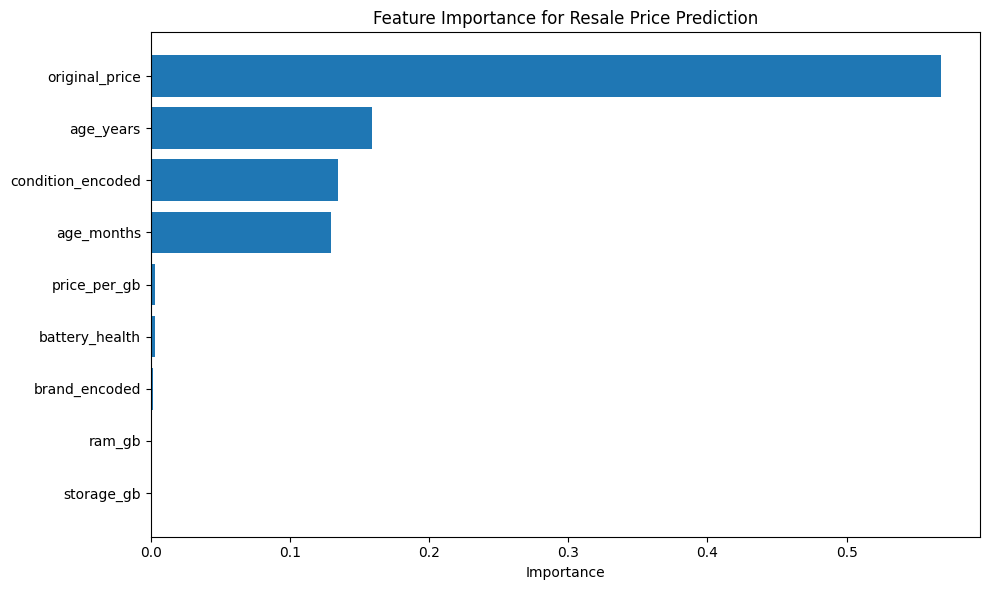


✅ Feature importance plot saved!


In [9]:
# If best model is Random Forest, show feature importance
if 'Random Forest' in best_model_name:
    importances = best_model.feature_importances_
    feature_importance_df = pd.DataFrame({
        'Feature': features,
        'Importance': importances
    }).sort_values('Importance', ascending=False)
    
    print("📊 Feature Importance:")
    print("="*50)
    print(feature_importance_df.to_string(index=False))
    
    # Plot feature importance
    import matplotlib.pyplot as plt
    plt.figure(figsize=(10, 6))
    plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'])
    plt.xlabel('Importance')
    plt.title('Feature Importance for Resale Price Prediction')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig('../app/static/plots/feature_importance.png', dpi=100)
    plt.show()
    print("\n✅ Feature importance plot saved!")

In [10]:
# Save everything
joblib.dump(best_model, '../models/model.pkl')
joblib.dump(scaler, '../models/scaler.pkl')
joblib.dump(features, '../models/features.pkl')
joblib.dump(le_brand, '../models/le_brand.pkl')
joblib.dump(le_condition, '../models/le_condition.pkl')

print("✅ Model saved successfully!")
print("\n📁 Files saved in 'models/' folder:")
print("  - model.pkl")
print("  - scaler.pkl")
print("  - features.pkl")
print("  - le_brand.pkl")
print("  - le_condition.pkl")

✅ Model saved successfully!

📁 Files saved in 'models/' folder:
  - model.pkl
  - scaler.pkl
  - features.pkl
  - le_brand.pkl
  - le_condition.pkl


In [11]:
# Test with sample data
test_data = pd.DataFrame([{
    'brand_encoded': le_brand.transform(['Apple'])[0],
    'age_months': 12,
    'ram_gb': 8,
    'storage_gb': 128,
    'battery_health': 85,
    'condition_encoded': le_condition.transform(['Good'])[0],
    'original_price': 50000,
    'price_per_gb': 50000 / 128,
    'age_years': 12 / 12
}])

# Scale and predict
test_scaled = scaler.transform(test_data[features])
prediction = best_model.predict(test_scaled)[0]

print("="*50)
print("🔮 SAMPLE PREDICTION TEST")
print("="*50)
print(f"Brand: Apple")
print(f"Age: 12 months")
print(f"RAM: 8 GB")
print(f"Storage: 128 GB")
print(f"Battery: 85%")
print(f"Condition: Good")
print(f"Original Price: ₹50,000")
print(f"\n💰 Predicted Resale Price: ₹{prediction:,.2f}")
print(f"📉 Depreciation: {(1 - prediction/50000)*100:.1f}%")

🔮 SAMPLE PREDICTION TEST
Brand: Apple
Age: 12 months
RAM: 8 GB
Storage: 128 GB
Battery: 85%
Condition: Good
Original Price: ₹50,000

💰 Predicted Resale Price: ₹36,773.80
📉 Depreciation: 26.5%
